In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans

C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split

In [5]:
%pip install tensorflow-datasets

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/5.3 MB ? eta -:--:--
   ----- ---------------------------------- 0.8/5.3 MB 2.0 MB/s eta 0:00:03
   ----------------------- ---------------- 3.1/5.3 MB 5.9 MB/s eta 0:00:01
   ---------------------------------------  5.2/5.3 MB 7.8 MB/s eta 0:00:01
   ---------------------------------------- 5.3/5.3 MB 6.8 MB/s  0:00:00
  Created wheel for promise: filename=promise-2.3-py3-none-any.whl size=21644 sha256=70fc8e9c5154733dc5a6f8fb0087aca2c4c91337a8e6913bf4f51073dec4f93d
  Stored in directory: c:\users\madhu\appdata\local\pip\cache\wheels\e7\e6\28\864bdfee5339dbd6ddcb5a186286a8e217648ec198bdf0097d
Successfully built pr

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import os
import PIL
import PIL.Image
import tensorflow as tf
import tensorflow_datasets as tfds

In [13]:
import os

fashion_folder = r"C:\Users\madhu\Desktop\CaliboPractice01\Data\Fashion"

print(os.listdir(fashion_folder))

['t10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz', 'train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz']


# TensorFlow Hands-on Practice: Fashion-MNIST Image Classification

## Problem Statement

The objective of this project is to develop a Deep Learning model using TensorFlow to classify clothing images into 10 different categories. The Fashion-MNIST dataset contains 70,000 grayscale images, each with a size of 28 × 28 pixels.

In this practice, the dataset is downloaded and loaded manually from compressed `.gz` files using Python. The data is then explored and preprocessed before building, training, and evaluating a neural network using TensorFlow and Keras.

## Objectives

1. Understand the Fashion-MNIST dataset and its structure.
2. Load training images, testing images, and their labels manually using Python.
3. Visualize images and understand their corresponding labels.
4. Preprocess image pixel values for model training.
5. Build a neural network using TensorFlow and Keras.
6. Train the model to classify clothing images.
7. Evaluate model performance using test data and accuracy.
8. Predict the clothing category of a new image.

## Dataset Details

- **Dataset:** Fashion-MNIST
- **Total images:** 70,000
- **Training images:** 60,000
- **Testing images:** 10,000
- **Image dimensions:** 28 × 28 pixels
- **Number of classes:** 10
- **Data format:** Compressed IDX files (`.gz`)

## Tools and Technologies

- Python
- NumPy
- Matplotlib
- TensorFlow
- Keras
- Jupyter Notebook

## Expected Outcome

A trained neural network capable of predicting one of the 10 clothing categories from a grayscale image. The model's performance will be evaluated using the testing dataset.

## Learning Outcome

This practice provides hands-on experience with manual dataset loading, data exploration, preprocessing, neural network construction, model training, evaluation, and prediction using TensorFlow.


In [18]:
import gzip
import struct
import numpy as np
import os

data_path = r"C:\Users\madhu\Desktop\CaliboPractice01\Data\Fashion"

def load_images(filename):
    with gzip.open(os.path.join(data_path, filename), "rb") as f:
        magic, num_images, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
        images = images.reshape(num_images, rows, cols)
    return images

def load_labels(filename):
    with gzip.open(os.path.join(data_path, filename), "rb") as f:
        magic, num_labels = struct.unpack(">II", f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)
    return labels

In [19]:
X_train = load_images("train-images-idx3-ubyte.gz")
y_train = load_labels("train-labels-idx1-ubyte.gz")

X_test = load_images("t10k-images-idx3-ubyte.gz")
y_test = load_labels("t10k-labels-idx1-ubyte.gz")

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


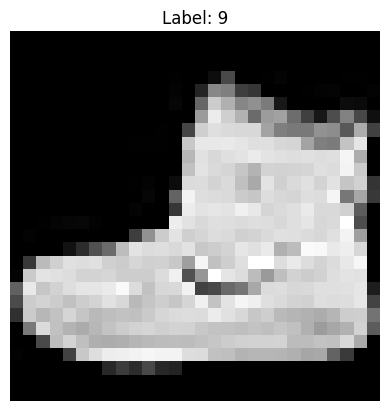

In [20]:
import matplotlib.pyplot as plt

plt.imshow(X_train[0], cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

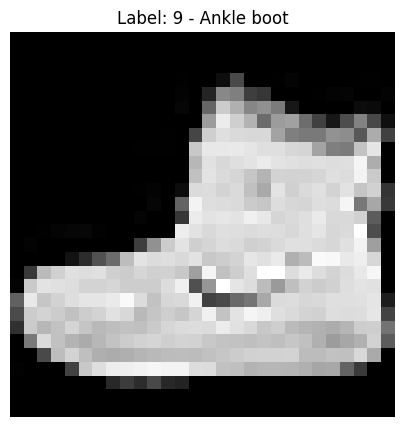

In [21]:
plt.figure(figsize=(5, 5))
plt.imshow(X_train[0], cmap="gray", interpolation="nearest")
plt.title(f"Label: {y_train[0]} - Ankle boot")
plt.axis("off")
plt.show()

In [22]:
# Normalize pixel values from 0–255 to 0–1
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Training data range:", X_train.min(), "to", X_train.max())
print("Testing data range:", X_test.min(), "to", X_test.max())

Training data range: 0.0 to 1.0
Testing data range: 0.0 to 1.0


### Step 2: Data Normalization

Normalization converts pixel values from the range 0–255 to 0–1 by dividing each pixel value by 255.

**Why?** It helps the neural network learn more effectively.

**Result:** Both training and testing images now have pixel values between 0 and 1.

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Display all class names
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Count images belonging to each class
unique_labels, counts = np.unique(y_train, return_counts=True)

for label, count in zip(unique_labels, counts):
    print(class_names[label], ":", count)

T-shirt/top : 6000
Trouser : 6000
Pullover : 6000
Dress : 6000
Coat : 6000
Sandal : 6000
Shirt : 6000
Sneaker : 6000
Bag : 6000
Ankle boot : 6000


### Step 3: Exploratory Data Analysis (EDA)

In this step, we examine the target labels and count the number of images in each clothing category.

**Purpose:** To understand the distribution of clothing classes and check whether some categories have more images than others.

### EDA Observation: Class Distribution

The training dataset contains 60,000 images across 10 clothing categories, with 6,000 images per category.

**Conclusion:** The dataset is balanced because every class has an equal number of images. No class has more images than another.

### EDA: Image Visualization

Visualized one sample image from each of the 10 clothing categories to understand the appearance and differences between classes.

**Purpose:** To inspect the images visually and understand what the model will learn to classify.

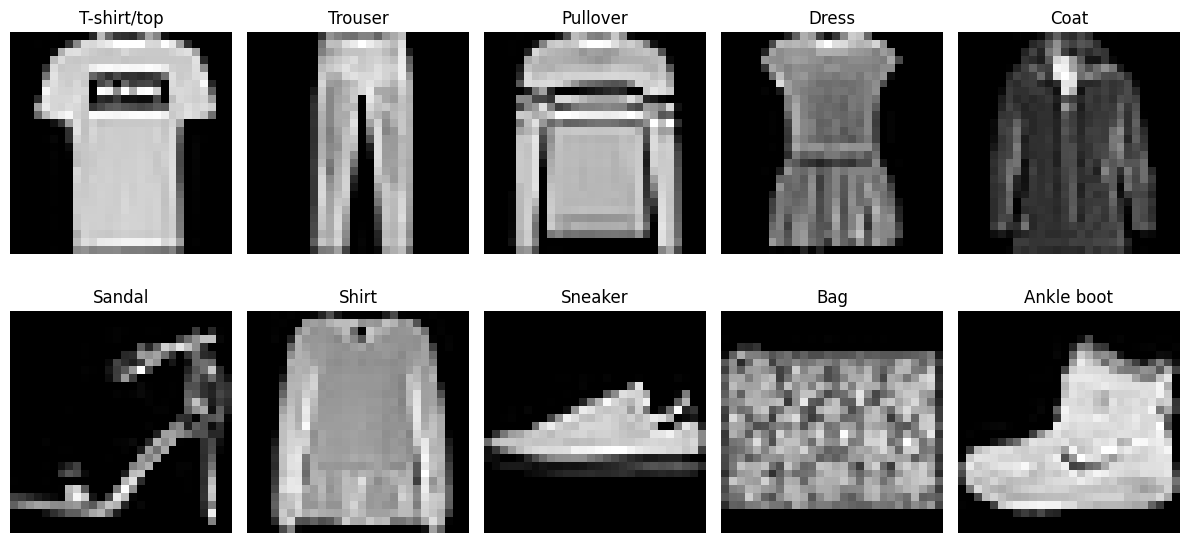

In [24]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Find the first image belonging to each class
    image_index = np.where(y_train == i)[0][0]

    plt.imshow(X_train[image_index], cmap="gray")
    plt.title(class_names[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

### Step 4: Data Quality Checks

Checked the training and testing images for missing values, verified the pixel value range, checked the label range, and confirmed the dataset sizes.

**Purpose:** To ensure that the data is valid and ready for model training.

In [25]:
# Check missing or invalid values
print("Training images contain NaN:", np.isnan(X_train).any())
print("Testing images contain NaN:", np.isnan(X_test).any())

# Check pixel value range
print("Training pixel range:", X_train.min(), "to", X_train.max())

# Check label range
print("Training label range:", y_train.min(), "to", y_train.max())
print("Testing label range:", y_test.min(), "to", y_test.max())

# Check dataset sizes
print("Training images:", len(X_train))
print("Testing images:", len(X_test))

Training images contain NaN: False
Testing images contain NaN: False
Training pixel range: 0.0 to 1.0
Training label range: 0 to 9
Testing label range: 0 to 9
Training images: 60000
Testing images: 10000


### Step 4: Data Quality Check — Observations

- No NaN values were found in the training or testing images.
- Normalized pixel values range from 0 to 1.
- Labels range from 0 to 9, representing the 10 clothing categories.
- The dataset contains 60,000 training images and 10,000 testing images.

**Conclusion:** The dataset is valid and ready for the next preprocessing step. No additional missing-value handling is required.


### Step 5: Train-Validation Split

The original training dataset was divided into 80% training data and 20% validation data.

- Training: 48,000 images
- Validation: 12,000 images
- Testing: 10,000 images

**Purpose:** The training set teaches the model, the validation set helps monitor its performance, and the test set evaluates its final performance.


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Validation images:", X_val.shape)
print("Validation labels:", y_val.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (48000, 28, 28)
Training labels: (48000,)
Validation images: (12000, 28, 28)
Validation labels: (12000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


### Step 6: Neural Network Model Building

Built a neural network using TensorFlow and Keras to classify Fashion-MNIST clothing images.

The model contains a Flatten layer, a hidden Dense layer with 128 neurons and ReLU activation, and an output Dense layer with 10 neurons and Softmax activation.

**Purpose:** To learn patterns from clothing images and predict their categories.

In [27]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Step 6: Model Summary — Observations

The neural network contains a Flatten layer, a hidden Dense layer with 128 neurons, and an output Dense layer with 10 neurons.

- Total parameters: 101,770
- Trainable parameters: 101,770
- Non-trainable parameters: 0

**Conclusion:** The model is ready to be compiled and trained to classify clothing images into 10 categories.

### Step 7: Model Compilation

The model was compiled using the Adam optimizer, sparse categorical crossentropy loss, and accuracy metric.

**Purpose:** To configure the learning process and define how the model's prediction errors and performance will be measured.

In [28]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


### Step 7: Model Compilation — Result

The model was compiled successfully using the Adam optimizer, sparse categorical crossentropy loss function, and accuracy metric.

**Observation:** TensorFlow displayed a GPU support warning because native Windows GPU support is limited in newer TensorFlow versions. This does not prevent model training; training can proceed using the CPU.

### Step 8: Model Training

The neural network was trained using 48,000 training images for 10 epochs, with a batch size of 32. The 12,000 validation images were used to monitor model performance after each epoch.

**Goal:** To help the model learn clothing patterns and monitor its accuracy and loss during training.

In [29]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8159 - loss: 0.5232 - val_accuracy: 0.8562 - val_loss: 0.4038
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8603 - loss: 0.3901 - val_accuracy: 0.8660 - val_loss: 0.3825
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8724 - loss: 0.3484 - val_accuracy: 0.8773 - val_loss: 0.3429
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8814 - loss: 0.3235 - val_accuracy: 0.8867 - val_loss: 0.3274
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8878 - loss: 0.3029 - val_accuracy: 0.8822 - val_loss: 0.3291
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8904 - loss: 0.2905 - val_accuracy: 0.8813 - val_loss: 0.3349
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8972 - loss: 0.2765 - val_accuracy: 0.8829 - val_loss: 0.3258
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9021 - loss: 0.2654 - 

In [31]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

In [32]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop]
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9114 - loss: 0.2382 - val_accuracy: 0.8965 - val_loss: 0.3000
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9149 - loss: 0.2273 - val_accuracy: 0.8965 - val_loss: 0.3108
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9171 - loss: 0.2213 - val_accuracy: 0.8975 - val_loss: 0.2971
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9212 - loss: 0.2133 - val_accuracy: 0.8986 - val_loss: 0.3040
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9208 - loss: 0.2073 - val_accuracy: 0.8935 - val_loss: 0.3281


### EarlyStopping — Training Observation

EarlyStopping monitored validation loss during training. The lowest validation loss observed through Epoch 5 was 0.2971 at Epoch 3.

Validation loss increased in some later epochs, so EarlyStopping continued monitoring for further improvement.

**Purpose:** To stop training when validation loss no longer improves and restore the best model weights.

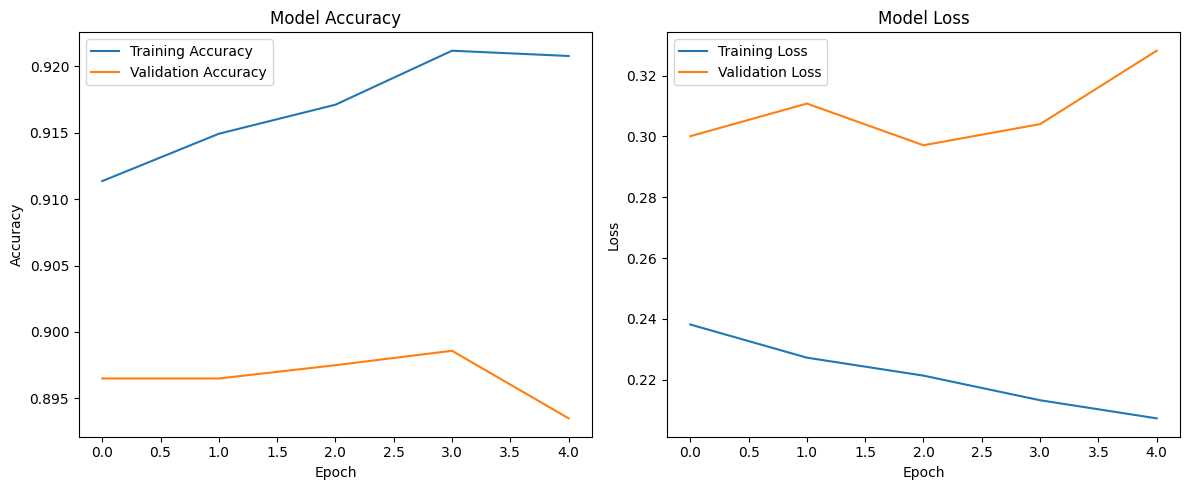

In [33]:

import matplotlib.pyplot as plt

# Plot accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


### Step: Visualize Training Performance

- Training accuracy increased while training loss decreased.
- Validation accuracy remained around 89% and decreased in the final epoch.
- Validation loss was lowest at Epoch 3 and increased afterward.
- These differences suggest possible overfitting.

**Conclusion:** The model learns the training data well, but its performance on unseen data does not improve consistently.

In [34]:

predictions = model.predict(X_test[:10])

for i in range(10):
    predicted_label = np.argmax(predictions[i])
    actual_label = y_test[i]

    print("Image:", i + 1)
    print("Predicted:", class_names[predicted_label])
    print("Actual:", class_names[actual_label])
    print("Correct:", predicted_label == actual_label)
    print()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
Image: 1
Predicted: Ankle boot
Actual: Ankle boot
Correct: True

Image: 2
Predicted: Pullover
Actual: Pullover
Correct: True

Image: 3
Predicted: Trouser
Actual: Trouser
Correct: True

Image: 4
Predicted: Trouser
Actual: Trouser
Correct: True

Image: 5
Predicted: Shirt
Actual: Shirt
Correct: True

Image: 6
Predicted: Trouser
Actual: Trouser
Correct: True

Image: 7
Predicted: Coat
Actual: Coat
Correct: True

Image: 8
Predicted: Shirt
Actual: Shirt
Correct: True

Image: 9
Predicted: Sandal
Actual: Sandal
Correct: True

Image: 10
Predicted: Sneaker
Actual: Sneaker
Correct: True



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


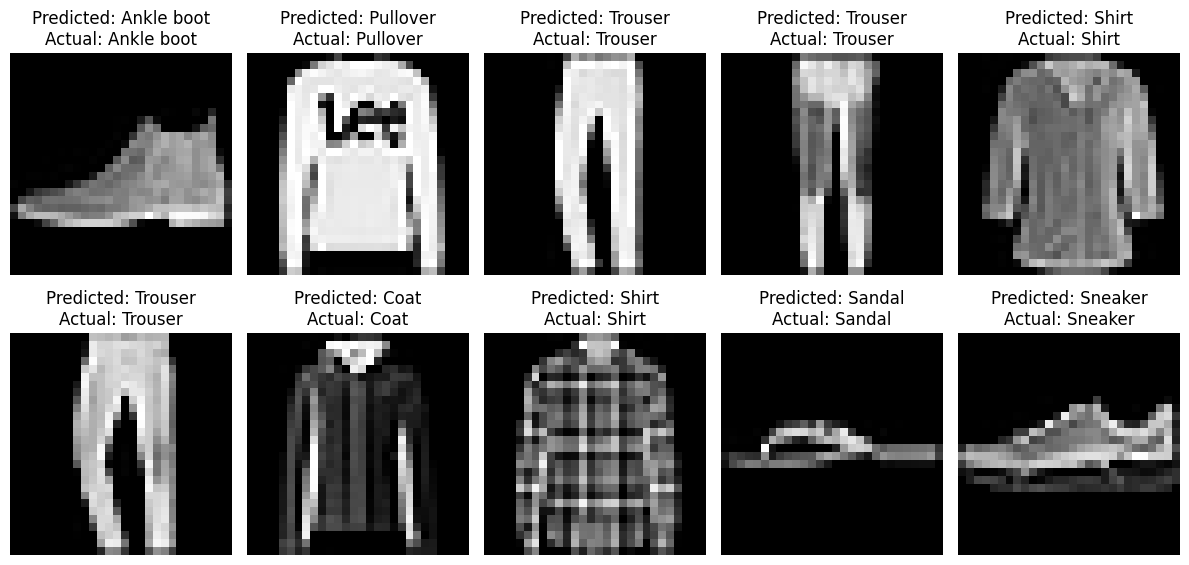

In [35]:

predictions = model.predict(X_test[:10])

plt.figure(figsize=(12, 6))

for i in range(10):
    predicted_label = np.argmax(predictions[i])

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    plt.title(
        f"Predicted: {class_names[predicted_label]}\n"
        f"Actual: {class_names[y_test[i]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


In [36]:
for i in range(10):
    predicted_label = np.argmax(predictions[i])
    confidence = np.max(predictions[i]) * 100

    print(
        f"Image {i + 1}: {class_names[predicted_label]} "
        f"({confidence:.2f}% confidence)"
    )

Image 1: Ankle boot (98.49% confidence)
Image 2: Pullover (99.94% confidence)
Image 3: Trouser (100.00% confidence)
Image 4: Trouser (100.00% confidence)
Image 5: Shirt (86.24% confidence)
Image 6: Trouser (100.00% confidence)
Image 7: Coat (99.39% confidence)
Image 8: Shirt (99.41% confidence)
Image 9: Sandal (99.99% confidence)
Image 10: Sneaker (99.99% confidence)


### Step: Prediction Confidence

The model predicted the clothing categories for the first 10 test images correctly. The confidence scores show the probabilities assigned to the predicted categories.

The highest confidence was approximately 100%, while the lowest was 86.24%.

**Conclusion:** The model can recognize these sample images with high confidence. However, overall performance must be evaluated using the complete test dataset.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


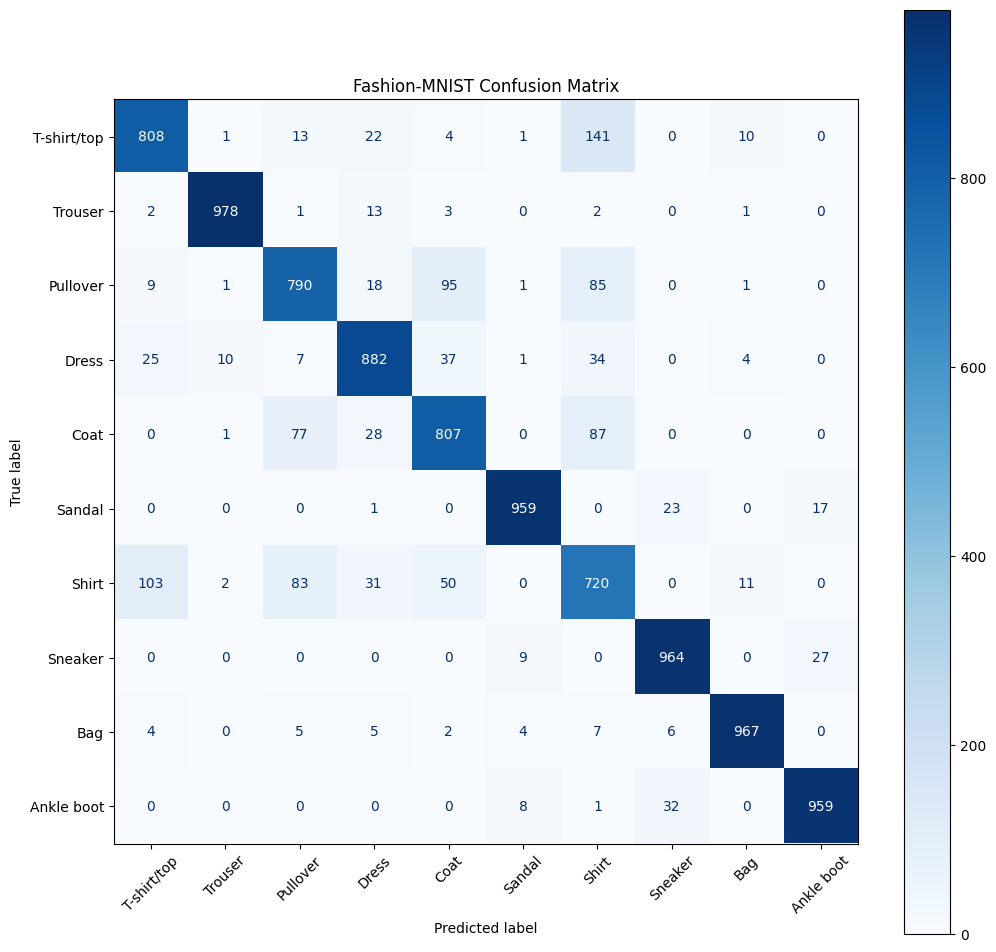

In [37]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

# Predict all test images
y_pred_prob = model.predict(X_test)

# Convert probabilities into predicted class labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 12))
display.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Fashion-MNIST Confusion Matrix")
plt.show()


In [38]:

# Total correct and incorrect predictions
correct = np.trace(cm)
total = np.sum(cm)
incorrect = total - correct

print("Total test images:", total)
print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)
print("Test accuracy:", round(correct / total * 100, 2), "%")


Total test images: 10000
Correct predictions: 8834
Incorrect predictions: 1166
Test accuracy: 88.34 %


In [39]:

# Copy the confusion matrix and remove diagonal values
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

# Find the largest misclassification count
actual_idx, predicted_idx = np.unravel_index(
    np.argmax(cm_errors), cm_errors.shape
)

print("Most confused categories:")
print("Actual category:", class_names[actual_idx])
print("Predicted category:", class_names[predicted_idx])
print("Number of mistakes:", cm_errors[actual_idx, predicted_idx])


Most confused categories:
Actual category: T-shirt/top
Predicted category: Shirt
Number of mistakes: 141


### Step: Confusion Matrix Analysis

- Total test images: 10,000
- Correct predictions: 8,834
- Incorrect predictions: 1,166
- Test accuracy: 88.34%
- Most confused categories: T-shirt/top and Shirt
- The model incorrectly classified 141 T-shirt/top images as Shirts.

**Conclusion:** The confusion matrix helps identify which clothing categories the model classifies incorrectly. Similar-looking clothing categories are harder to distinguish.

In [40]:

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))


              precision    recall  f1-score   support

 T-shirt/top       0.85      0.81      0.83      1000
     Trouser       0.98      0.98      0.98      1000
    Pullover       0.81      0.79      0.80      1000
       Dress       0.88      0.88      0.88      1000
        Coat       0.81      0.81      0.81      1000
      Sandal       0.98      0.96      0.97      1000
       Shirt       0.67      0.72      0.69      1000
     Sneaker       0.94      0.96      0.95      1000
         Bag       0.97      0.97      0.97      1000
  Ankle boot       0.96      0.96      0.96      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



### Step: Classification Report

The model achieved approximately 88% overall test accuracy.

- Precision measures the correctness of positive predictions for each category.
- Recall measures how many actual examples of a category were correctly identified.
- F1-score combines precision and recall.
- Support shows the number of actual test samples in each category.

Trouser achieved the highest F1-score of 0.98, while Shirt achieved the lowest F1-score of 0.69.

**Conclusion:** The model performs well on most categories but has difficulty distinguishing some similar-looking clothing items.

In [41]:

model.save("fashion_mnist_model.keras")

print("Model saved successfully!")


Model saved successfully!


In [42]:

import tensorflow as tf

loaded_model = tf.keras.models.load_model("fashion_mnist_model.keras")

print("Saved model loaded successfully!")


Saved model loaded successfully!


In [43]:

test_loss, test_accuracy = loaded_model.evaluate(X_test, y_test)

print("Loaded Model Test Accuracy:", round(test_accuracy * 100, 2), "%")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8834 - loss: 0.3303
Loaded Model Test Accuracy: 88.34 %


### Step: Save and Load the Model

The trained model was saved in `.keras` format. The saved model can be loaded later and used for predictions without training again.

**Conclusion:** Saving a model allows us to reuse the trained model for future predictions.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


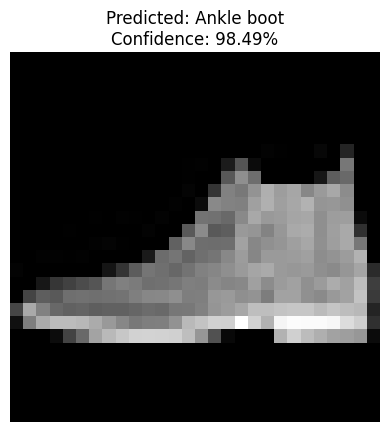

Actual category: Ankle boot


In [44]:

# Select one test image
image_index = 0
image = X_test[image_index]

# Predict using the loaded model
prediction = loaded_model.predict(image.reshape(1, 28, 28))

# Get predicted category and confidence
predicted_label = np.argmax(prediction[0])
confidence = np.max(prediction[0]) * 100

# Display the image
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.title(
    f"Predicted: {class_names[predicted_label]}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Actual category:", class_names[y_test[image_index]])


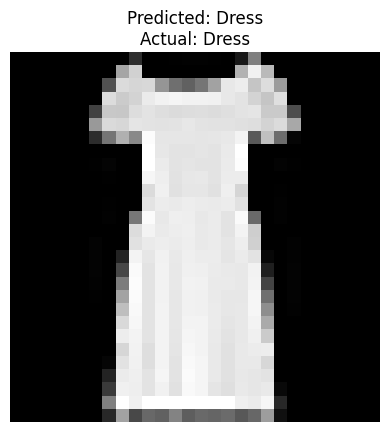

Confidence: 100.0 %
Correct prediction: True


In [45]:

import random

# Select a random test image
image_index = random.randint(0, len(X_test) - 1)
image = X_test[image_index]

# Predict the category
prediction = loaded_model.predict(image.reshape(1, 28, 28), verbose=0)

predicted_label = np.argmax(prediction[0])
confidence = np.max(prediction[0]) * 100
actual_label = y_test[image_index]

# Display the image
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.title(
    f"Predicted: {class_names[predicted_label]}\n"
    f"Actual: {class_names[actual_label]}"
)
plt.show()

print("Confidence:", round(confidence, 2), "%")
print("Correct prediction:", predicted_label == actual_label)


# Fashion-MNIST Image Classification Using TensorFlow

## Project Summary

Built a neural network using TensorFlow and Keras to classify grayscale clothing images into 10 categories.

### Steps Completed
1. Loaded the Fashion-MNIST dataset from compressed `.gz` files.
2. Explored image shapes, labels, and class distribution.
3. Normalized pixel values from 0–255 to 0–1.
4. Split the training data into training and validation sets.
5. Built a neural network using Flatten and Dense layers.
6. Trained the model using Adam and sparse categorical cross-entropy.
7. Used EarlyStopping to monitor validation loss.
8. Evaluated the model using test accuracy, a confusion matrix, precision, recall, and F1-score.
9. Saved and reloaded the trained model.
10. Tested predictions on individual clothing images.

### Final Results
- **Test accuracy:** 88.34%
- **Correct predictions:** 8,834 out of 10,000 test images
- **Incorrect predictions:** 1,166
- **Best-performing category by F1-score:** Trouser (0.98)
- **Most challenging category by F1-score:** Shirt (0.69)

### Conclusion
The trained neural network successfully classified clothing images into 10 categories, achieving 88.34% test accuracy. The confusion matrix showed that similar-looking clothing categories, especially T-shirt/top and Shirt, were more difficult to distinguish.